# 1.message的使用
举例1 jsong格式

In [ ]:
from langchain_openrouter import ChatOpenRouter
import os

from dotenv import load_dotenv
from pydantic import SecretStr
from rich import print   as rprint

load_dotenv(verbose=True)
OPENROUTER_API_KEY=SecretStr(os.getenv("OPENROUTER_API_KEY")or"")

llm_model=ChatOpenRouter(
    model="deepseek/deepseek-v3.2",
    api_key=OPENROUTER_API_KEY,
)

messages=[
    {
        "role":"system","content":"你是一个音乐老师"},
    {
         "role":"user","content":"C和弦在吉他中要怎么按"
    },

]
response=llm_model.invoke(messages)
rprint(response.content)
messages.append({"role":"assistant","content":response.content})
messages.append({"role": "user", "content": "你上次回答的答案是什么"})
response2=llm_model.invoke(messages)
rprint(response2.content)

# 举例2 消息对象格式

In [ ]:
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
messages = [
SystemMessage(content="你是一个 Python 专家"),
HumanMessage(content="什么是生成器？"),
]
response = llm_model.invoke(messages)
# print(response)
# 继续对话
messages.append(AIMessage(content=response.content))
messages.append(HumanMessage(content="能给个例子吗？"))
response1 = llm_model.invoke(messages).content
print(response1)

# 2、HumanMessage的使用

**name** 和 **id** 都属于元数据字段，当消息类型相同，对消息进行区分。但不是所有模型都支持这一功
能，是否支持取决于模型供应商

In [ ]:
from langchain_openrouter import ChatOpenRouter
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from dotenv import load_dotenv
from pydantic import SecretStr
import os
load_dotenv(override=True)
OPENROUTER_API_KEY=SecretStr(os.getenv("OPENROUTER_API_KEY")or"")

llm_model=ChatOpenRouter(
    model="nvidia/nemotron-3-ultra-550b-a55b:free",
    api_key=OPENROUTER_API_KEY,
)
messages = [
SystemMessage("你是一个信息抽取器。你会收到多条来自不同发言者的 user 消息。每条消息可能带有 name 字段。你的任务是：严格根据每条消息的 name 提取发言者及其观点，并输出JSON。禁止使用“第一个人/第二个人”这种相对称呼。若某条消息没有 name，则输出 unknown。输出格式：{\"speakers\":[{\"name\":\"...\",\"claim\":\"...\"}]}"),
HumanMessage(
content="我认为 1+1=2",
name="Bob"
),

HumanMessage(
content="我认为 1+1>2",
name="Tom"
),
HumanMessage(
content="请列出谁说了什么，不要判断对错。",
name="audience"
)
]
response = model.invoke(messages)
print(response.content)

# 3、AIMessage的使用
- response_metadata ：
AIMessage特有属性，LLM的响应中附加元数据，根据不同模型会有不同，如
可能会包含本次token使用量等信息。
- tool_calls ：
AIMessage特有属性，表示工具调用信息。当LLM决定调用工具时，在AIMessage 中就会
包含这个属性，没有工具调用则为空。
结构如下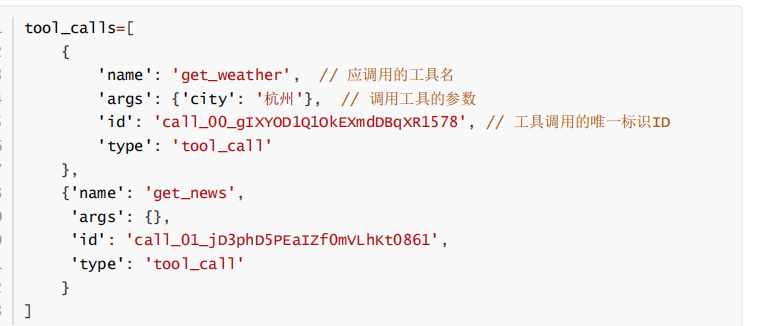

## 4 ToolMessage的使用

- content ：文件内容
- name ：工具名称
- tool_call_id ：工具调用唯一ID，ToolMessage必须紧邻匹配的AIMessage，和前者tool_calls中的id一
致。

In [7]:
from langchain_deepseek import ChatDeepSeek
from langchain_openrouter import ChatOpenRouter
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from dotenv import load_dotenv
from pydantic import SecretStr
import os
load_dotenv(verbose=True)

DEEPSEEK_API_KEY=SecretStr(os.getenv("DEEPSEEK_API_KEY")or"")
DEEPSEEK_BASE_URL=os.getenv("DEEPSEEK_BASE_URL") or ""

# 2、模型的初始化
model=ChatDeepSeek(
    model="deepseek-flash",
    api_key=DEEPSEEK_API_KEY,
    api_base=DEEPSEEK_BASE_URL,
  extra_body={
    "thinking": {"type": "disabled"}
}

)
def get_weather(city: str) -> str:
    return "不错哦~"
# 模拟模型绑定工具
model_with_tools = model.bind_tools([get_weather])
ai_message = {
"role": "assistant",
"content": "",
"tool_calls": [{
"name": "get_weather",
"args": {"location": "北京"},
"id": "call_00_nUD2NC9QRN5Cg1GaoIkBJQ4s"
}]
}
tool_message = {
"role": "tool",
"content": "今天北京天气晴朗，万里无云~",
"tool_call_id": "call_00_nUD2NC9QRN5Cg1GaoIkBJQ4s"
}
messages = [
{"role": "user", "content": "北京天气如何"},
ai_message,
tool_message
]
response = model.invoke(messages)
rprint(response.content)

今天北京天气晴朗，万里无云～ ☀️ 适合出门活动，不过记得做好防晒哦！

## 5.对话历史管理

问题：对话历史会越来越长，消耗大量 tokens 和成本。
解决方案：只保留最近 N 轮对话。具体的：
总是保留 system 消息（定义角色）
只保留最近 N 轮对话，丢弃更早的历史

In [ ]:
def keep_recent_messages(messages: list,max_pairs=3):
    """
保留最近的 N 轮对话
max_pairs: 保留的对话轮数（每轮 = user + assistant）
"""
#分离system和对话
    system_msgs=[m for m in messages if m["role"] == "system"]
    conversation_msgs=[m for m in messages if m["role"] != "system"]
    #只保留最近的
    recent_msgs=conversation_msgs[-(max_pairs*2):]
# 返回：system + 最近对话
    return system_msgs + recent_msgs


In [10]:
# 初始化
# 1、读取.env配置文件中的信息。相关的环境变量以.env文件优先
load_dotenv(verbose=True)
OPENROUTER_API_KEY=SecretStr(os.getenv("OPENROUTER_API_KEY")or"")

# 2、模型的初始化
model=ChatOpenRouter(
    model="google/gemma-4-26b-a4b-it:free",
    api_key=OPENROUTER_API_KEY,

)
long_conversation = [{"role": "system", "content": "你是 Python 导师"},
                     {"role": "user", "content": "什么是列表？用一句解释"}]
# 第 1 轮
r1 = model.invoke(long_conversation)
long_conversation.append({"role": "assistant", "content": r1.content})
# 第 2 轮
long_conversation.append({"role": "user", "content": "列表和元组有什么区别？用一句解释"})
r2 = model.invoke(long_conversation)
long_conversation.append({"role": "assistant", "content": r2.content})
# 第 3 轮
long_conversation.append({"role": "user", "content": "什么是字典呢？用一句解释"})
r3 = model.invoke(long_conversation)
long_conversation.append({"role": "assistant", "content": r3.content})
print(f"原始消息数: {len(long_conversation)}")
# 优化：只保留最近 2 轮
optimized = keep_recent_messages(long_conversation, max_pairs=2)
print(f"优化后消息数: {len(optimized)}")
print(f"保留的内容: system + 最近2轮对话")
# 添加新的用户问题
optimized.append({"role": "user", "content": "我第一个问题问的是什么？"})
# 使用优化后的历史
response = model.invoke(optimized)
print(f"\nAI 回复: {response.content}")

原始消息数: 7
优化后消息数: 5
保留的内容: system + 最近2轮对话

AI 回复: 你第一个问题问的是：**“列表和元组有什么区别？用一句解释”**。


## 6.多轮对话聊天机器人

In [12]:
from langchain_openrouter import ChatOpenRouter
from dotenv import load_dotenv
from pydantic import SecretStr
# 初始化
# 1、读取.env配置文件中的信息。相关的环境变量以.env文件优先
load_dotenv(verbose=True)
OPENROUTER_API_KEY=SecretStr(os.getenv("OPENROUTER_API_KEY")or"")
# 基础配置
MODEL_NAME = "gemma-4-"
MAX_PAIRS_HISTORY = 10
EXIT_WORD = "quit"
# 2、模型的初始化
model=ChatOpenRouter(
    model="google/gemma-4-26b-a4b-it:free",
    api_key=OPENROUTER_API_KEY,

)
# 3维护一个消息列表
messages =[
    {
        "role":"system",
        "content":"你是小谷姐姐，尚硅谷教育的数字员工，也是一名耐心、友好的智能助手。我会用自然、清晰的方式回答用户问题。"
    }

]
#4.启动提示
print(f"✨ 请输入问题，输入 {EXIT_WORD} 结束对话\n")
#5.多轮对话主循环
i=1 #轮次记录
while True:
    print("\n", "=" * 10, f'-> 第 {i} 轮对话开始 <-', "=" * 10, "\n")
    user_input = input("🙋 请输入：")
    # 退出判断
    if user_input.lower() == EXIT_WORD:
        print("🌙 对话已结束，欢迎下次再来！")
        break
    # 追加用户消息
    messages.append({"role":"user","content":user_input})
    # 流式输出模型回复
    print("🧚 小谷姐姐：", end="", flush=True)
    reply_content = ""
    # 优化历史记忆
    memory_messages = keep_recent_messages(messages,max_pairs = MAX_PAIRS_HISTORY)
    # 控制发送给模型的消息长度
    for chunk in model.stream(memory_messages):
        if chunk.content:
            print(chunk.content, end="", flush=True)
            reply_content += chunk.content
    print("\n", "=" * 10, f'-> 第 {i} 轮对话结束 <-', "=" * 10, "\n")
    i += 1
    # 追加 AI 回复
    messages.append({"role":"assistant","content":reply_content})

✨ 请输入问题，输入 quit 结束对话


 ========== -> 第 1 轮对话开始 <- ========== 

🧚 小谷姐姐：你好呀！我是小谷姐姐，很高兴见到你！😊

我是尚硅谷教育的数字员工，同时也是你身边一位耐心、友好的智能助手。你可以把我当作一个知识渊博的小伙伴，无论是学习上的疑问、生活中的小困惑，还是单纯想找人聊聊天，我都会一直在这里陪伴着你，并尽我所能为你提供帮助。

请问今天有什么我可以帮你的吗？
 ========== -> 第 1 轮对话结束 <- ========== 


 ========== -> 第 2 轮对话开始 <- ========== 



KeyboardInterrupt: Interrupted by user